# Component 3 — Modelling EDA and Chronological Split

This notebook freezes the modelling population, creates chronological development/validation/test partitions and performs train-safe modelling EDA. It consumes `monthly_model_features.parquet` from `06_feature_engineering.ipynb`.

## Split policy and safeguards

- Rows must pass the feature-engineering minimum-history rule.
- **Training:** all eligible target months through 2022-12.
- **Validation:** eligible target months during 2023.
- **Final test:** eligible target months during 2024; its target distribution and target relationships remain sealed here.
- Expanding-window folds ending in 2020, 2021 and 2022 are defined inside training for later model comparison and tuning.
- No random split, imputation, scaling, category encoding, resampling, feature selection or model fitting occurs in this notebook.
- All learned preprocessing in later notebooks must fit on the relevant training partition only.

In [1]:
import importlib.util, subprocess, sys
packages={'pandas':'pandas>=2.0,<3','numpy':'numpy>=1.24,<3','pyarrow':'pyarrow>=14,<22','matplotlib':'matplotlib>=3.7,<4'}
missing=[spec for module,spec in packages.items() if importlib.util.find_spec(module) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
print('Modelling-EDA dependencies are available.')

Modelling-EDA dependencies are available.


In [2]:
from __future__ import annotations
import hashlib, json, os, sys
from pathlib import Path
import matplotlib
if 'IPython' not in sys.modules: matplotlib.use('Agg')
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display=print
pd.set_option('display.max_columns',120); plt.style.use('seaborn-v0_8-whitegrid')
COLORS={'train':'#4e79a7','validation':'#f28e2b','test':'#bab0ac','accent':'#59a14f'}
VALIDATION_START=pd.Timestamp('2023-01-01'); TEST_START=pd.Timestamp('2024-01-01'); TEST_END=pd.Timestamp('2024-12-31')

## 1. Locate and validate the feature artifact

In [3]:
def find_component_root(start:Path)->Path:
    for anchor in [start.resolve(),*start.resolve().parents]:
        for candidate in [anchor,anchor/'component - 3',anchor/'J26-DS-350'/'component - 3']:
            if (candidate/'Notebooks').is_dir() and (candidate/'src').is_dir(): return candidate.resolve()
    raise FileNotFoundError('Component 3 repository root was not found.')
IN_COLAB='google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive'); ROOT=Path('/content/drive/MyDrive/FishGuard-C3')
else: ROOT=find_component_root(Path.cwd())
PROCESSED_DIR=Path(os.getenv('FISHGUARD_C3_PROCESSED_DIR',str(ROOT/'data'/'processed'))).resolve()
FEATURE_AUDIT_DIR=Path(os.getenv('FISHGUARD_C3_FEATURE_OUTPUT',str(ROOT/'outputs'/'audit'/'feature_engineering'))).resolve()
EVIDENCE_DIR=Path(os.getenv('FISHGUARD_C3_MODEL_EDA_OUTPUT',str(ROOT/'outputs'/'audit'/'modelling_eda_split'))).resolve()
FIGURE_DIR=Path(os.getenv('FISHGUARD_C3_MODEL_EDA_FIGURES',str(ROOT/'outputs'/'figures'/'modelling_eda_split'))).resolve()
for directory in [PROCESSED_DIR,EVIDENCE_DIR,FIGURE_DIR]: directory.mkdir(parents=True,exist_ok=True)
INPUT_PATH=PROCESSED_DIR/'monthly_model_features.parquet'
OUTPUT_PATH=PROCESSED_DIR/'monthly_model_features_split.parquet'
DICTIONARY_PATH=FEATURE_AUDIT_DIR/'feature_dictionary.csv'
if not INPUT_PATH.is_file(): raise FileNotFoundError(f'Missing {INPUT_PATH}. Run 06_feature_engineering.ipynb first.')
if not DICTIONARY_PATH.is_file(): raise FileNotFoundError(f'Missing {DICTIONARY_PATH}.')
features=pd.read_parquet(INPUT_PATH); dictionary=pd.read_csv(DICTIONARY_PATH)
required={'month_start','spatial_cell_id','species_model','gear_model','target_log1p_median_catch','target_median_catch_weight_kg','eligible_minimum_history'}
missing=required-set(features.columns)
if missing: raise KeyError(f'Missing modelling fields: {sorted(missing)}')
if set(dictionary.column)!=set(features.columns): raise ValueError('Feature dictionary and Parquet schema do not match.')
features['month_start']=pd.to_datetime(features.month_start,errors='raise')
source_sha256=hashlib.sha256(INPUT_PATH.read_bytes()).hexdigest()
print('Rows:',f'{len(features):,}','Columns:',len(features.columns)); print('SHA-256:',source_sha256)

Mounted at /content/drive
Rows: 10,050 Columns: 88
SHA-256: 23a1d78fc31f6f47341ed1f363a934a3fc4a78b58283d5910dfb73b72d5ebbef


## 2. Freeze the eligible modelling population and assign splits

In [4]:
model_data=features.loc[features.eligible_minimum_history].copy()
outside_scope=model_data.month_start>TEST_END
if outside_scope.any(): raise ValueError(f'{int(outside_scope.sum())} rows occur after the declared final test period.')
model_data['data_split']=np.select(
    [model_data.month_start<VALIDATION_START,(model_data.month_start>=VALIDATION_START)&(model_data.month_start<TEST_START),(model_data.month_start>=TEST_START)&(model_data.month_start<=TEST_END)],
    ['train','validation','test'],default='outside_scope')
assert not model_data.data_split.eq('outside_scope').any()
assert not model_data.duplicated(['month_start','spatial_cell_id','species_model','gear_model']).any()
assert model_data.groupby('data_split').month_start.agg(['min','max']).loc['train','max'] < model_data.groupby('data_split').month_start.agg(['min','max']).loc['validation','min']
assert model_data.groupby('data_split').month_start.agg(['min','max']).loc['validation','max'] < model_data.groupby('data_split').month_start.agg(['min','max']).loc['test','min']
model_data['data_split']=pd.Categorical(model_data.data_split,categories=['train','validation','test'],ordered=True)
model_data=model_data.sort_values(['month_start','spatial_cell_id','species_model','gear_model']).reset_index(drop=True)
model_data.to_parquet(OUTPUT_PATH,index=False)
print('Frozen rows:',f'{len(model_data):,}'); display(model_data.groupby('data_split',observed=True).size().rename('rows'))

Frozen rows: 9,930


,rows
data_split,
train,8197
validation,792
test,941


## 3. Audit split boundaries without inspecting test outcomes

In [5]:
summary=[]
for split,part in model_data.groupby('data_split',observed=True):
    summary.append({'data_split':str(split),'rows':len(part),'observed_months':part.month_start.nunique(),'first_target_month':part.month_start.min().date(),'last_target_month':part.month_start.max().date(),'spatial_cells':part.spatial_cell_id.nunique(),'species':part.species_model.nunique(),'gears':part.gear_model.nunique(),'target_summary_status':'sealed' if str(split)=='test' else 'available_for_development_eda'})
split_summary=pd.DataFrame(summary)
year_coverage=(model_data.assign(year=model_data.month_start.dt.year).groupby(['data_split','year'],observed=True).agg(rows=('target_log1p_median_catch','size'),months=('month_start','nunique'),spatial_cells=('spatial_cell_id','nunique'),species=('species_model','nunique')).reset_index())
split_summary.to_csv(EVIDENCE_DIR/'split_summary.csv',index=False)
year_coverage.to_csv(EVIDENCE_DIR/'split_year_coverage.csv',index=False)
display(split_summary); display(year_coverage)

,data_split,rows,observed_months,first_target_month,last_target_month,spatial_cells,species,gears,target_summary_status
0,train,8197,55,2018-01-01,2022-11-01,65,58,3,available_for_development_eda
1,validation,792,11,2023-02-01,2023-12-01,27,32,3,available_for_development_eda
2,test,941,12,2024-01-01,2024-12-01,31,32,3,sealed


,data_split,year,rows,months,spatial_cells,species
0,train,2018,2848,12,64,42
1,train,2019,3968,12,63,42
2,train,2020,733,10,32,28
3,train,2021,272,10,19,22
4,train,2022,376,11,23,25
5,validation,2023,792,11,27,32
6,test,2024,941,12,31,32


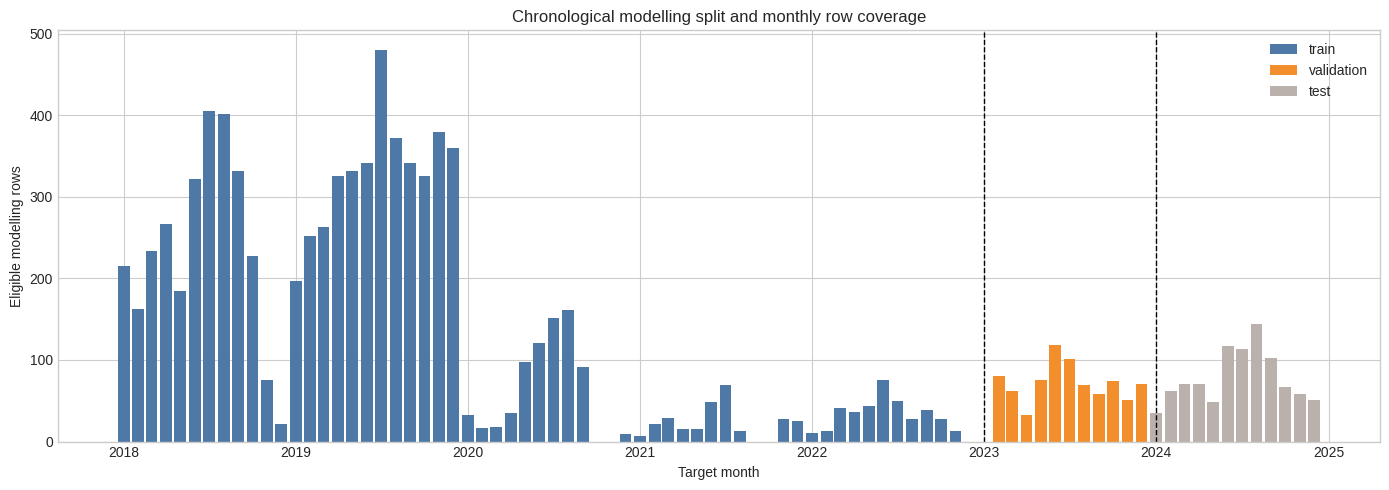

In [6]:
monthly_counts=(model_data.groupby(['month_start','data_split'],observed=True).size().rename('rows').reset_index())
fig,ax=plt.subplots(figsize=(14,5))
for split,color in COLORS.items():
    if split not in ('train','validation','test'): continue
    part=monthly_counts.loc[monthly_counts.data_split==split]; ax.bar(part.month_start,part.rows,width=25,color=color,label=split)
ax.axvline(VALIDATION_START,color='black',linestyle='--',linewidth=1); ax.axvline(TEST_START,color='black',linestyle='--',linewidth=1)
ax.set_title('Chronological modelling split and monthly row coverage'); ax.set_xlabel('Target month'); ax.set_ylabel('Eligible modelling rows'); ax.legend()
fig.tight_layout(); fig.savefig(FIGURE_DIR/'chronological_split_timeline.png',dpi=200,bbox_inches='tight'); plt.show()

## 4. Training and validation target analysis

The final 2024 test target is deliberately excluded from every summary and plot below.

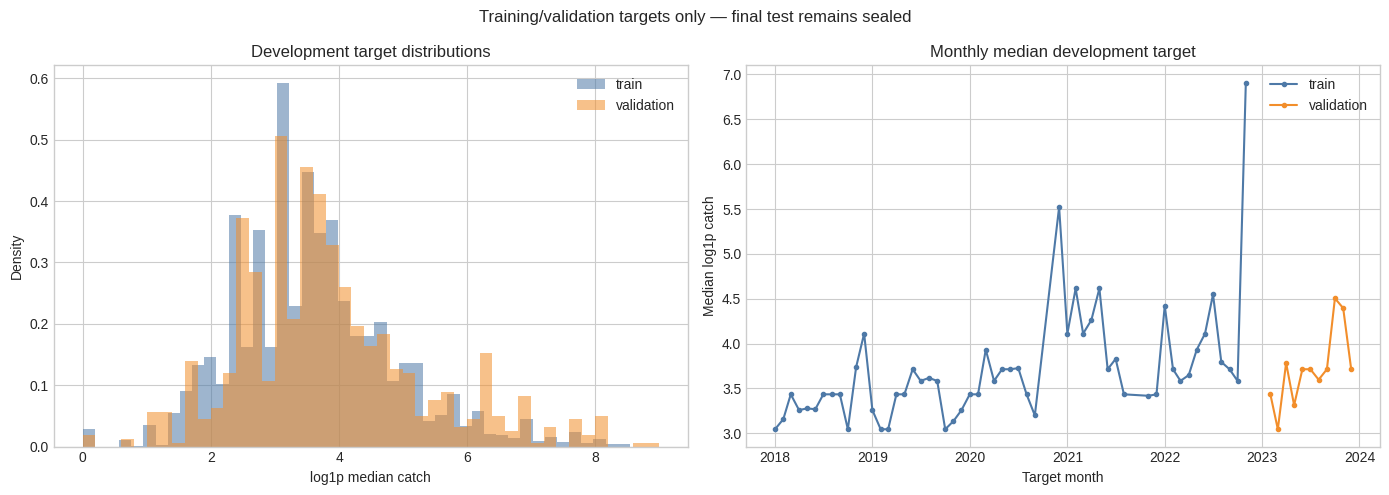

,data_split,rows,raw_mean,raw_median,raw_p90,raw_p99,log1p_mean,log1p_median,log1p_std
0,train,8197,104.256832,30.0,190.0,1700.0,3.579048,3.433987,1.266873
1,validation,792,181.881629,37.5,400.0,3000.0,3.822136,3.650658,1.444994


In [7]:
development=model_data.loc[model_data.data_split.isin(['train','validation'])].copy()
target_rows=[]
for split,part in development.groupby('data_split',observed=True):
    raw=part.target_median_catch_weight_kg; transformed=part.target_log1p_median_catch
    target_rows.append({'data_split':str(split),'rows':len(part),'raw_mean':raw.mean(),'raw_median':raw.median(),'raw_p90':raw.quantile(.9),'raw_p99':raw.quantile(.99),'log1p_mean':transformed.mean(),'log1p_median':transformed.median(),'log1p_std':transformed.std()})
target_summary=pd.DataFrame(target_rows)
target_summary.to_csv(EVIDENCE_DIR/'development_target_summary.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(14,5))
for split,color in [('train',COLORS['train']),('validation',COLORS['validation'])]:
    values=development.loc[development.data_split==split,'target_log1p_median_catch']; axes[0].hist(values,bins=45,density=True,alpha=.55,label=split,color=color)
monthly=development.groupby(['month_start','data_split'],observed=True).target_log1p_median_catch.median().reset_index()
for split,color in [('train',COLORS['train']),('validation',COLORS['validation'])]:
    part=monthly.loc[monthly.data_split==split]; axes[1].plot(part.month_start,part.target_log1p_median_catch,marker='o',markersize=3,label=split,color=color)
axes[0].set_title('Development target distributions'); axes[0].set_xlabel('log1p median catch'); axes[0].set_ylabel('Density'); axes[0].legend()
axes[1].set_title('Monthly median development target'); axes[1].set_xlabel('Target month'); axes[1].set_ylabel('Median log1p catch'); axes[1].legend()
fig.suptitle('Training/validation targets only — final test remains sealed'); fig.tight_layout(); fig.savefig(FIGURE_DIR/'development_target_diagnostics.png',dpi=200,bbox_inches='tight'); plt.show(); display(target_summary)

## 5. Predictor readiness using training data only

In [8]:
predictors=dictionary.loc[dictionary.role=='candidate_predictor','column'].tolist()
missing_predictors=sorted(set(predictors)-set(model_data.columns))
if missing_predictors: raise KeyError(f'Dictionary predictors missing from data: {missing_predictors}')
train=model_data.loc[model_data.data_split=='train'].copy(); validation=model_data.loc[model_data.data_split=='validation'].copy()
numeric_predictors=[column for column in predictors if pd.api.types.is_numeric_dtype(train[column])]
categorical_predictors=[column for column in predictors if column not in numeric_predictors]
screening=[]
for column in numeric_predictors:
    pair=train[[column,'target_log1p_median_catch']].dropna()
    rho=pair[column].corr(pair.target_log1p_median_catch,method='spearman') if len(pair)>=3 and pair[column].nunique()>1 else np.nan
    screening.append({'feature':column,'train_non_missing':len(pair),'train_missing_percent':train[column].isna().mean()*100,'train_unique':train[column].nunique(dropna=True),'train_spearman_with_target':rho})
numeric_screening=pd.DataFrame(screening).sort_values('train_spearman_with_target',key=lambda values:values.abs(),ascending=False)
numeric_screening.to_csv(EVIDENCE_DIR/'training_numeric_screening.csv',index=False)
display(numeric_screening.head(20))

,feature,train_non_missing,train_missing_percent,train_unique,train_spearman_with_target
27,group_catch_rolling_mean_3m,4740,42.173966,751,0.587509
28,group_catch_rolling_mean_6m,5443,33.597658,1343,0.583664
2,group_median_catch_weight_kg_lag_1,3426,58.204221,260,0.545807
3,group_median_catch_weight_kg_lag_2,2853,65.194583,241,0.544563
4,group_median_catch_weight_kg_lag_3,2534,69.086251,235,0.541319
5,group_median_catch_weight_kg_lag_4,2228,72.819324,228,0.498523
7,group_median_catch_weight_kg_lag_6,1963,76.052214,213,0.477271
6,group_median_catch_weight_kg_lag_5,2093,74.466268,217,0.455657
31,species_catch_rolling_mean_6m,7911,3.489081,550,0.408187
30,species_catch_rolling_mean_3m,7841,4.343052,359,0.396284


In [9]:
drift=[]
for column in numeric_predictors:
    train_q1,train_median,train_q3=train[column].quantile([.25,.5,.75]); validation_median=validation[column].median(); iqr=train_q3-train_q1
    drift.append({'feature':column,'train_missing_percent':train[column].isna().mean()*100,'validation_missing_percent':validation[column].isna().mean()*100,'missing_percent_change':validation[column].isna().mean()*100-train[column].isna().mean()*100,'train_median':train_median,'validation_median':validation_median,'standardized_median_shift':np.nan if pd.isna(iqr) or iqr==0 else (validation_median-train_median)/iqr})
numeric_drift=pd.DataFrame(drift); numeric_drift['absolute_standardized_shift']=numeric_drift.standardized_median_shift.abs(); numeric_drift=numeric_drift.sort_values('absolute_standardized_shift',ascending=False)
numeric_drift.to_csv(EVIDENCE_DIR/'train_validation_numeric_drift.csv',index=False)
category_rows=[]
for column in categorical_predictors:
    known=set(train[column].dropna().astype(str)); val=validation[column].astype('string'); unseen=val.notna()&~val.astype(str).isin(known)
    category_rows.append({'feature':column,'train_categories':len(known),'validation_categories':validation[column].nunique(dropna=True),'unseen_validation_categories':len(set(val.loc[unseen].dropna().astype(str))),'unseen_validation_rows':int(unseen.sum()),'unseen_validation_percent':unseen.mean()*100})
category_coverage=pd.DataFrame(category_rows)
category_coverage.to_csv(EVIDENCE_DIR/'train_validation_category_coverage.csv',index=False)
display(numeric_drift.head(15)); display(category_coverage)

,feature,train_missing_percent,validation_missing_percent,missing_percent_change,train_median,validation_median,standardized_median_shift,absolute_standardized_shift
72,year,0.000000,0.000000,0.000000,2019.000000,2023.000000,4.000000,4.000000
76,months_since_start,0.000000,0.000000,0.000000,19.000000,69.000000,3.333333,3.333333
0,cell_lat_center,0.000000,0.000000,0.000000,6.550000,6.350000,-1.000000,1.000000
1,cell_lon_center,0.000000,0.000000,0.000000,79.550000,79.350000,-0.666667,0.666667
37,global_catch_rolling_mean_6m,0.000000,0.000000,0.000000,27.333333,31.500000,0.641026,0.641026
59,global_env_median_sst_c_lag_5,8.381115,9.595960,1.214845,28.860591,28.075411,-0.631331,0.631331
47,cell_env_median_sst_c_lag_5,31.828718,33.585859,1.757141,28.857662,28.116428,-0.540310,0.540310
29,species_catch_history_months_available,0.000000,0.000000,0.000000,6.000000,5.000000,-0.500000,0.500000
20,global_median_catch_weight_kg_lag_1,0.000000,0.000000,0.000000,25.500000,32.000000,0.433333,0.433333
22,global_median_catch_weight_kg_lag_3,2.378919,7.828283,5.449364,26.000000,32.000000,0.428571,0.428571


,feature,train_categories,validation_categories,unseen_validation_categories,unseen_validation_rows,unseen_validation_percent
0,species_model,58,32,4,12,1.515152
1,gear_model,3,3,0,0,0.000000
2,climate_season,4,4,0,0,0.000000


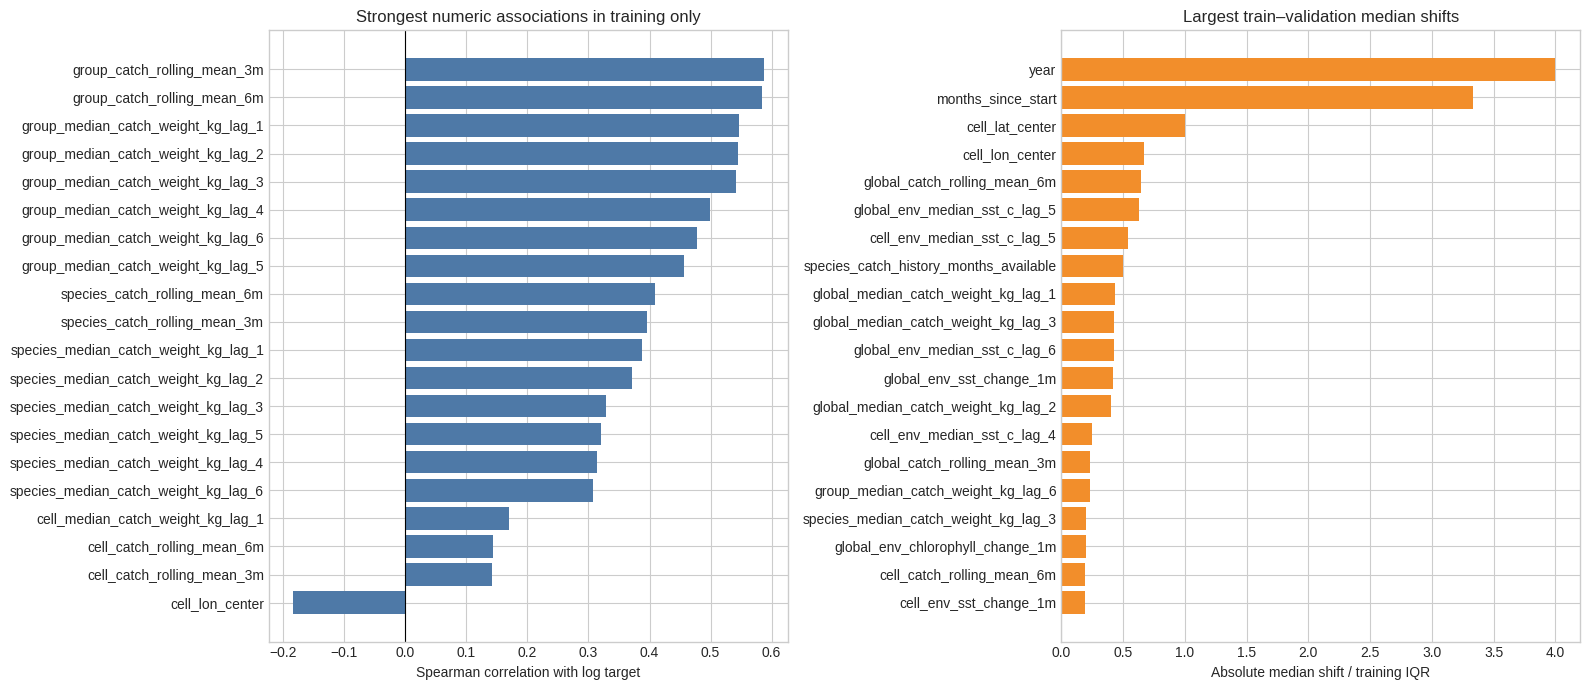

In [10]:
fig,axes=plt.subplots(1,2,figsize=(16,7))
top_corr=numeric_screening.dropna(subset=['train_spearman_with_target']).head(20).sort_values('train_spearman_with_target')
axes[0].barh(top_corr.feature,top_corr.train_spearman_with_target,color=COLORS['train']); axes[0].axvline(0,color='black',linewidth=.8); axes[0].set_title('Strongest numeric associations in training only'); axes[0].set_xlabel('Spearman correlation with log target')
top_drift=numeric_drift.dropna(subset=['absolute_standardized_shift']).head(20).sort_values('absolute_standardized_shift')
axes[1].barh(top_drift.feature,top_drift.absolute_standardized_shift,color=COLORS['validation']); axes[1].set_title('Largest train–validation median shifts'); axes[1].set_xlabel('Absolute median shift / training IQR')
fig.tight_layout(); fig.savefig(FIGURE_DIR/'predictor_screening_and_drift.png',dpi=200,bbox_inches='tight'); plt.show()

## 6. Define expanding-window cross-validation folds

In [11]:
folds=[]
for fold_id,validation_year in enumerate([2020,2021,2022],start=1):
    train_mask=(model_data.data_split=='train')&(model_data.month_start.dt.year<validation_year)
    fold_validation_mask=(model_data.data_split=='train')&(model_data.month_start.dt.year==validation_year)
    fold_train=model_data.loc[train_mask]; fold_validation=model_data.loc[fold_validation_mask]
    folds.append({'fold_id':fold_id,'train_start':fold_train.month_start.min().date(),'train_end':fold_train.month_start.max().date(),'validation_start':fold_validation.month_start.min().date(),'validation_end':fold_validation.month_start.max().date(),'train_rows':len(fold_train),'validation_rows':len(fold_validation)})
cv_folds=pd.DataFrame(folds)
assert (cv_folds.train_rows>0).all() and (cv_folds.validation_rows>0).all()
cv_folds.to_csv(EVIDENCE_DIR/'expanding_window_cv_folds.csv',index=False)
display(cv_folds)

,fold_id,train_start,train_end,validation_start,validation_end,train_rows,validation_rows
0,1,2018-01-01,2019-12-01,2020-01-01,2020-12-01,6816,733
1,2,2018-01-01,2020-12-01,2021-01-01,2021-12-01,7549,272
2,3,2018-01-01,2021-12-01,2022-01-01,2022-11-01,7821,376


## 7. Save split checks, viva findings and manifest

In [12]:
split_checks=pd.DataFrame([
 {'check':'eligible rows only','passed':model_data.eligible_minimum_history.all(),'detail':f'{len(model_data):,} rows'},
 {'check':'unique panel keys','passed':not model_data.duplicated(['month_start','spatial_cell_id','species_model','gear_model']).any(),'detail':'month × cell × species × gear'},
 {'check':'strict chronological ordering','passed':train.month_start.max()<validation.month_start.min()<model_data.loc[model_data.data_split=='test','month_start'].min(),'detail':'train before validation before test'},
 {'check':'test target not summarized','passed':'test' not in target_summary.data_split.tolist(),'detail':'2024 outcome remains sealed'},
 {'check':'predictor roles from dictionary','passed':len(predictors)>0 and not set(predictors)&{'target_log1p_median_catch','target_median_catch_weight_kg','diagnostic_total_catch_weight_kg','diagnostic_record_count'},'detail':f'{len(predictors)} candidate predictors'},
 {'check':'cross-validation stays inside training','passed':pd.to_datetime(cv_folds.validation_end).max()<VALIDATION_START,'detail':'fold validation years 2020–2022'}])
assert split_checks.passed.all(),split_checks.loc[~split_checks.passed].to_dict('records')
split_checks.to_csv(EVIDENCE_DIR/'split_leakage_checks.csv',index=False)
findings=pd.DataFrame([
 {'finding':'Frozen modelling population','result':f'{len(model_data):,} eligible rows'},
 {'finding':'Development training period','result':f"{train.month_start.min().date()} to {train.month_start.max().date()} ({len(train):,} rows)"},
 {'finding':'Validation period','result':f"{validation.month_start.min().date()} to {validation.month_start.max().date()} ({len(validation):,} rows)"},
 {'finding':'Final test period','result':f"2024; {int((model_data.data_split=='test').sum()):,} rows; outcomes sealed during development EDA"},
 {'finding':'Internal model-comparison design','result':'Three expanding-window folds with validation years 2020, 2021 and 2022'},
 {'finding':'Sampling limitation','result':'2018–2019 contain substantially more rows than later years; report time-based metrics and avoid random splitting'},
 {'finding':'Preprocessing boundary','result':'Imputation, encoding, scaling and feature selection must be fitted separately within each training fold'},
 {'finding':'Next stage','result':'Train leakage-safe baselines and candidate regression models; use 2023 for selection and 2024 once for final evaluation'}])
findings.to_csv(EVIDENCE_DIR/'modelling_eda_findings.csv',index=False)
output_sha256=hashlib.sha256(OUTPUT_PATH.read_bytes()).hexdigest()
manifest={'created_utc':pd.Timestamp.now(tz='UTC').isoformat(),'runtime':'Google Colab' if IN_COLAB else 'Local Windows','input':INPUT_PATH.name,'input_sha256':source_sha256,'output':OUTPUT_PATH.name,'output_sha256':output_sha256,'eligible_rows':len(model_data),'split_boundaries':{'train_end':'2022-12-31','validation_start':'2023-01-01','validation_end':'2023-12-31','test_start':'2024-01-01','test_end':'2024-12-31'},'test_target_status':'sealed_not_analyzed','candidate_predictors':len(predictors),'categorical_predictors':categorical_predictors,'numeric_predictors':len(numeric_predictors),'cv_validation_years':[2020,2021,2022],'preprocessing_fitted':False,'models_fitted':False,'source_artifact_modified':False,'figures':sorted(p.name for p in FIGURE_DIR.glob('*.png')),'evidence':sorted(p.name for p in EVIDENCE_DIR.glob('*.csv'))}
with (EVIDENCE_DIR/'modelling_eda_split_manifest.json').open('w',encoding='utf-8') as f: json.dump(manifest,f,indent=2)
display(split_checks); display(findings); print('Saved split artifact:',OUTPUT_PATH)

,check,passed,detail
0,eligible rows only,True,"9,930 rows"
1,unique panel keys,True,month × cell × species × gear
2,strict chronological ordering,True,train before validation before test
3,test target not summarized,True,2024 outcome remains sealed
4,predictor roles from dictionary,True,80 candidate predictors
5,cross-validation stays inside training,True,fold validation years 2020–2022


,finding,result
0,Frozen modelling population,"9,930 eligible rows"
1,Development training period,"2018-01-01 to 2022-11-01 (8,197 rows)"
2,Validation period,2023-02-01 to 2023-12-01 (792 rows)
3,Final test period,2024; 941 rows; outcomes sealed during develop...
4,Internal model-comparison design,Three expanding-window folds with validation y...
5,Sampling limitation,2018–2019 contain substantially more rows than...
6,Preprocessing boundary,"Imputation, encoding, scaling and feature sele..."
7,Next stage,Train leakage-safe baselines and candidate reg...


Saved split artifact: /content/drive/MyDrive/FishGuard-C3/data/processed/monthly_model_features_split.parquet


## Viva interpretation

Random splitting would allow later months and repeated fishery patterns to influence earlier predictions, producing optimistic performance. This chronological design simulates deployment: learn from the past, select models on a later year, and evaluate once on the newest untouched year. Uneven sampling across years remains a limitation, so later evaluation must report MAE/RMSE on the log target and interpretable kilogram-scale errors after inverse transformation, alongside time- and subgroup-level diagnostics.